# EDA: данные для агента, который проверяет поиск Альфа-Онлайн/Мобайл после релизов

Агент прогоняет фиксированный набор запросов, берёт топ-3, оценивает позиции (разметка Полины или LLM-судья), считает R3 и NDCG@3 и подсвечивает просадки относительно прошлого релиза. Поиск мы не обучаем. EDA отвечает на четыре вопроса, каждый заканчивается решением для проекта.

**Данные.** Данных банка пока нет. Каталог фич (48 карточек, 13 разделов) написан вручную, это допущение; метки «запрос → фича» в нём проставлены правилами. Метрики и просадки смотрим на WANDS (реальная выдача с разметкой 0/1/2), судью — на ESCI LLM-judged. Все числа относятся к прокси.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mlsd_course.eda.catalog import (
    b77ru_queries,
    build_qrels,
    load_catalog,
    ssq_queries,
    template_queries,
)
from mlsd_course.eda.drops import DROP_KINDS, delta_ndcg, rank, release, uniform_confusion
from mlsd_course.eda.judge import agreement, row_normalized
from mlsd_course.eda.loaders import load_banking77_ru, load_esci_judge, load_ssq_ru, load_wands
from mlsd_course.eda.ranking import evaluate_run, ndcg_at_k, r_at_k
from mlsd_course.eda.retrieval import BM25, CharTfidf, top_k_run

FIG = "../reports/eda/"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.options.display.float_format = "{:.3f}".format

## 1. Что тестируем
**Вопрос:** покрывает ли тестовый набор запросов все разделы и фичи банка и какие запросы трудные для поиска?

In [2]:
cat = load_catalog()
sec = dict(zip(cat["feature_id"], cat["section"], strict=True))
qs = pd.concat(
    [template_queries(cat), b77ru_queries(load_banking77_ru(), cat), ssq_queries(load_ssq_ru())],
    ignore_index=True,
)
qs["query_id"] = range(len(qs))
qs["n_words"] = qs["text"].str.split().str.len()
x = qs.explode("targets").dropna(subset=["targets"]).assign(section=lambda d: d["targets"].map(sec))
cover = pd.crosstab(x["section"], x["source"]).assign(карточек=cat["section"].value_counts())
natural = (
    x[x["source"] != "шаблон"]["targets"].value_counts().reindex(cat["feature_id"], fill_value=0)
)
print(
    f"запросов: {len(qs)}; вне каталога (ssq_ru без цели): {(qs['targets'].str.len() == 0).sum()}"
)
print(
    "карточки без единого «живого» запроса:",
    cat.set_index("feature_id").loc[natural.index[natural == 0], "title"].tolist(),
)
print(qs.groupby("source")["n_words"].median().rename("медиана слов").to_string())
cover

запросов: 3935; вне каталога (ssq_ru без цели): 471
карточки без единого «живого» запроса: ['Перевод по номеру телефона', 'ИИС']
source
banking77_ru   5.000
ssq_ru         8.000
шаблон         2.000


source,banking77_ru,ssq_ru,шаблон,карточек
section,,,,
Валюта,210,3,56,3
Инвестиции,0,98,36,2
Ипотека,0,19,20,1
Карты,485,8,124,7
Кредиты,0,12,52,3
Налоги,0,128,20,1
Платежи и переводы,145,58,124,7
Пополнение,346,0,80,5
Профиль и безопасность,369,0,92,5


,ndcg3,n
страта,,
шаблон: раскладка,0.122,213
banking77_ru,0.563,2160
шаблон: опечатка,0.653,213
ssq_ru,0.687,452
шаблон: с брендом,0.706,213
шаблон: чистый,0.707,213


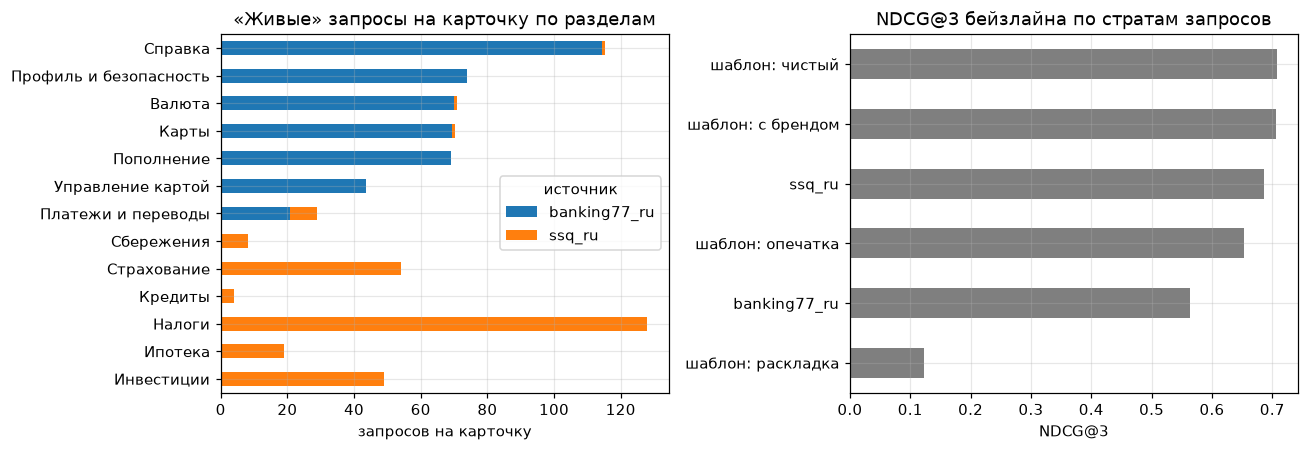

In [3]:
# Где поиск ломается: лексический бейзлайн (TF-IDF по символьным n-граммам) по стратам запросов.
inq = qs[qs["targets"].str.len() > 0].reset_index(drop=True)
run = top_k_run(
    CharTfidf(cat["doc"].tolist()).scores(inq["text"].tolist()),
    inq["query_id"].tolist(),
    cat["feature_id"].tolist(),
    k=3,
)
m1 = evaluate_run(run, build_qrels(inq, cat)).merge(inq[["query_id", "source", "stratum"]])
m1["страта"] = np.where(m1["source"] == "шаблон", "шаблон: " + m1["stratum"], m1["source"])
hard = (
    m1.groupby("страта")[["ndcg3"]]
    .mean()
    .assign(n=m1["страта"].value_counts())
    .sort_values("ndcg3")
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
cover[["banking77_ru", "ssq_ru"]].div(cover["карточек"], axis=0).sort_values(
    "banking77_ru"
).plot.barh(stacked=True, ax=ax[0])
ax[0].legend(title="источник")
ax[0].set(title="«Живые» запросы на карточку по разделам", xlabel="запросов на карточку", ylabel="")
hard["ndcg3"].plot.barh(ax=ax[1], color="tab:gray")
ax[1].set(title="NDCG@3 бейзлайна по стратам запросов", xlabel="NDCG@3", ylabel="")
fig.tight_layout()
fig.savefig(FIG + "q1_coverage.png")
hard

**Вывод.** Открытые источники перекошены: banking77_ru даёт только карты, переводы и сервис, ssq_ru — только продукты; на кредиты (12 фраз) и сбережения (25) живых запросов почти нет, у 2 карточек нет ни одного, 471 из 923 фраз ssq_ru вне каталога. Живые фразы длиннее поисковых (медиана 5–8 слов против 2 у шаблонов). Самые трудные страты — неверная раскладка (NDCG@3 0,12 против 0,71 у чистых) и длинные разговорные фразы (0,56).

**Решение:** набор собираем с Полиной по квоте на **каждый раздел**, а не по источнику: реальные частые запросы плюс обязательные страты «опечатка», «раскладка», «вне каталога» (~10% каждая). Объём — из вопроса 3, квоты по разделам — в сводке в конце.

## 2. Что считать правильной выдачей
**Вопрос:** сколько правильных ответов бывает у запроса и хватит ли бинарной метки «релевантно / нет»?

WANDS: запросов без точного ответа 21.0%, с < 3 точными 35.2%
BM25 топ-3: R3 (rel ≥ 1) = 0.883, R3 (только rel = 2) = 0.402, NDCG@3 = 0.723
ESCI, метки людей: {'E': 0.515, 'S': 0.331, 'I': 0.111, 'C': 0.042}
каталог: фич в разделе 1–7; запросов ssq_ru с ≥ 2 целями 10


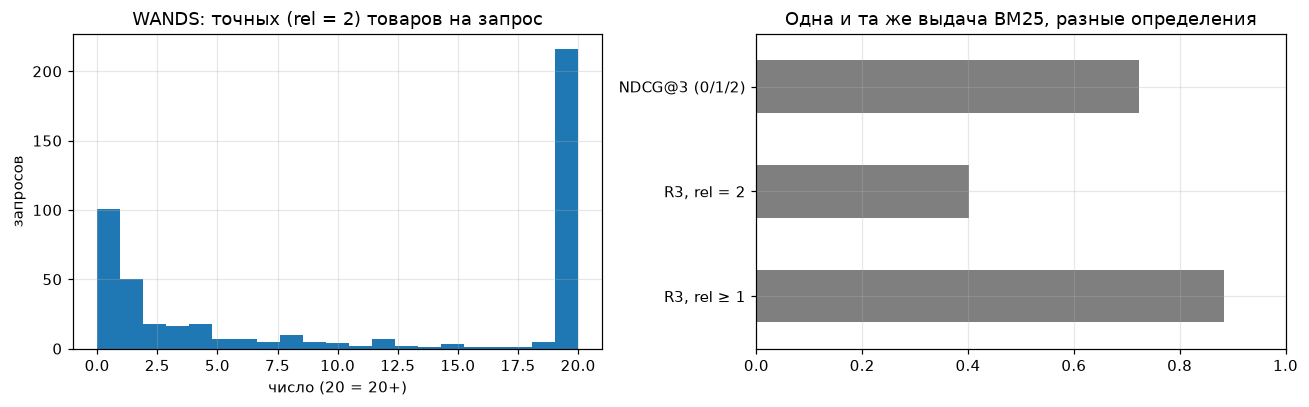

In [4]:
w = load_wands()
lab = w["label"]
per_q = lab.groupby("query_id")["rel"].agg(
    exact=lambda s: (s == 2).sum(), partial=lambda s: (s == 1).sum()
)
prod = w["product"]
bm25 = BM25((prod["product_name"].fillna("") + " " + prod["product_class"].fillna("")).tolist())
S = bm25.scores(w["query"]["query"].tolist())
pid = {p: i for i, p in enumerate(prod["product_id"])}
qrow = {q: i for i, q in enumerate(w["query"]["query_id"])}
# Кандидаты запроса — все размеченные товары (≥ 10), ранжируем их по BM25: так вся выдача размечена.
cands = {
    q: (
        g["product_id"].to_numpy(),
        g["rel"].to_numpy(),
        S[qrow[q], g["product_id"].map(pid).to_numpy()],
    )
    for q, g in lab.groupby("query_id")
    if len(g) >= 10
}
ideal = {q: sorted(c[1].tolist(), reverse=True) for q, c in cands.items()}
base = {q: rank(*c) for q, c in cands.items()}
top3 = {q: [r for _, r in s[:3]] for q, s in base.items()}
r3_soft = np.mean([r_at_k(t) for t in top3.values()])
r3_strict = np.mean([r_at_k([int(r == 2) for r in t]) for t in top3.values()])
ndcg = np.mean([ndcg_at_k(top3[q], 3, ideal[q]) for q in top3])
print(
    f"WANDS: запросов без точного ответа {(per_q['exact'] == 0).mean():.1%}, с < 3 точными {(per_q['exact'] < 3).mean():.1%}"
)
print(
    f"BM25 топ-3: R3 (rel ≥ 1) = {r3_soft:.3f}, R3 (только rel = 2) = {r3_strict:.3f}, NDCG@3 = {ndcg:.3f}"
)

esci = load_esci_judge()["calibration"]
print("ESCI, метки людей:", esci["human_label"].value_counts(normalize=True).round(3).to_dict())
ssq_multi = qs.loc[qs["source"] == "ssq_ru", "targets"].str.len()
print(
    f"каталог: фич в разделе {cat['section'].value_counts().min()}–{cat['section'].value_counts().max()}; запросов ssq_ru с ≥ 2 целями {(ssq_multi >= 2).sum()}"
)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
per_q["exact"].clip(upper=20).plot.hist(bins=21, ax=ax[0], color="tab:blue")
ax[0].set(
    title="WANDS: точных (rel = 2) товаров на запрос", xlabel="число (20 = 20+)", ylabel="запросов"
)
pd.Series({"R3, rel ≥ 1": r3_soft, "R3, rel = 2": r3_strict, "NDCG@3 (0/1/2)": ndcg}).plot.barh(
    ax=ax[1], color="tab:gray"
)
ax[1].set(title="Одна и та же выдача BM25, разные определения", xlim=(0, 1))
fig.tight_layout()
fig.savefig(FIG + "q2_relevance.png");

**Вывод.** Правильный ответ не один: у 21% запросов WANDS точного товара нет вовсе, у 35% их меньше трёх, а у остальных — десятки; в ESCI треть пар люди отметили как «замену» (S). Одна и та же выдача даёт R3 0,88 или 0,40 в зависимости от того, засчитываем ли смежную позицию. Повторной разметки людьми в прокси нет, согласие человек–человек придётся мерить самим.

**Решение:** шкала **0/1/2** (целевая / смежная / нерелевантная) плюс метка «подходящей фичи нет»; основная метрика — NDCG@3, R3 отчитываем в двух вариантах (rel ≥ 1 и rel = 2). Двойная разметка ~15% запросов, прежде всего на границе 1 ↔ 2.

## 3. Что считать поломкой
**Вопрос:** насколько NDCG@3 меняется от нейтрального релиза и насколько — от реальной поломки топ-3?

In [5]:
SIGMA = 0.05  # нейтральный релиз: скоры поиска дрожат на ~5%
neutral = np.array(
    [list(delta_ndcg(base, release(cands, SIGMA, seed=s)[0], ideal).values()) for s in range(20)]
)
broken = {}
for kind in DROP_KINDS:
    cur, hit = release(cands, SIGMA, seed=100, kind=kind, share=1.0)
    d = delta_ndcg(base, cur, ideal)
    broken[kind] = np.array([d[q] for q in hit])
TAU = 0.2
tbl = pd.DataFrame(
    {
        k: {"средний ΔNDCG@3": v.mean(), f"доля Δ ≤ −{TAU}": (v <= -TAU).mean()}
        for k, v in broken.items()
    }
).T
tbl.loc["нейтральный релиз"] = [neutral.mean(), (neutral <= -TAU).mean()]
print(
    f"нейтральный релиз меняет топ-3 у {np.mean([[a[:3] != b[:3] for a, b in zip(base.values(), release(cands, SIGMA, 0)[0].values(), strict=True)]]):.0%} запросов"
)
tbl

нейтральный релиз меняет топ-3 у 84% запросов


,средний ΔNDCG@3,доля Δ ≤ −0.2
swap_1_3,-0.031,0.130
shift_best_4,-0.095,0.219
evict_1,-0.334,0.647
evict_all,-0.613,0.817
нейтральный релиз,-0.001,0.031


,сломано 5% запросов,сломано 10% запросов,сломано 20% запросов,порог |ΔNDCG@3|
запросов в наборе,,,,
25,0.242,0.365,0.550,0.031
50,0.307,0.474,0.625,0.023
100,0.435,0.626,0.715,0.015
200,0.554,0.730,0.844,0.011
300,0.717,0.791,0.894,0.008
400,0.811,0.831,0.988,0.006


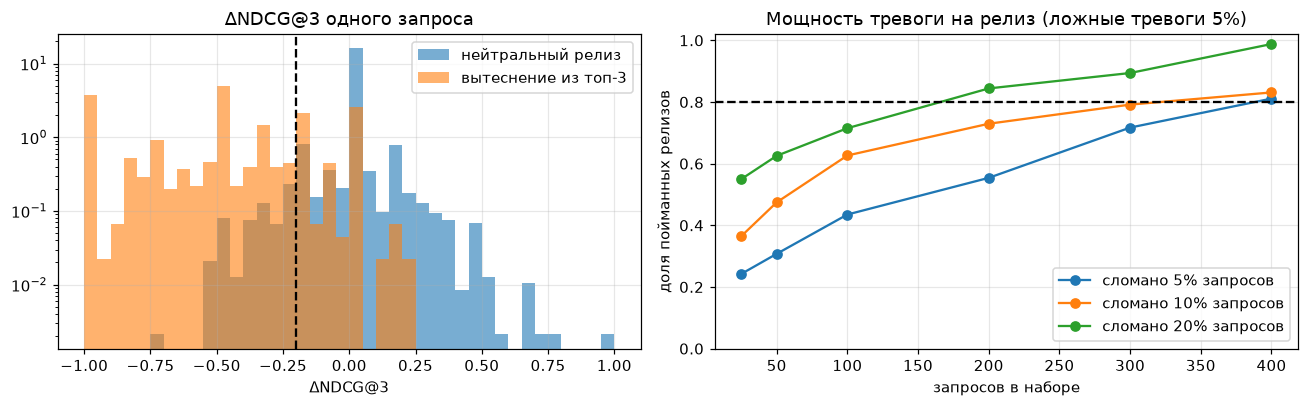

In [6]:
# Сигнал на релиз: средний ΔNDCG@3 по набору из n запросов. Порог — 5-й перцентиль нейтральных релизов.
rng = np.random.default_rng(0)
mix = {
    s: [
        delta_ndcg(base, release(cands, SIGMA, seed=200 + i, kind=k, share=s)[0], ideal)
        for i, k in enumerate(DROP_KINDS)
    ]
    for s in (0.05, 0.1, 0.2)
}
qids = np.array(list(cands))
sizes = [25, 50, 100, 200, 300, 400]
power = {}
for s, runs in mix.items():
    bro = np.array([[r[q] for q in qids] for r in runs])
    power[f"сломано {s:.0%} запросов"] = []
    for n in sizes:
        idx = [rng.choice(len(qids), n, replace=False) for _ in range(2000)]
        null = np.array([neutral[rng.integers(len(neutral)), i].mean() for i in idx])
        alt = np.array([bro[rng.integers(len(bro)), i].mean() for i in idx])
        power[f"сломано {s:.0%} запросов"].append((alt < np.quantile(null, 0.05)).mean())
power = pd.DataFrame(power, index=pd.Index(sizes, name="запросов в наборе"))
thr = {
    n: -np.quantile(
        [
            neutral[rng.integers(len(neutral)), rng.choice(len(qids), n, replace=False)].mean()
            for _ in range(2000)
        ],
        0.05,
    )
    for n in sizes
}

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(
    neutral.ravel(), bins=40, range=(-1, 1), density=True, alpha=0.6, label="нейтральный релиз"
)
ax[0].hist(
    np.concatenate([broken["evict_1"], broken["evict_all"]]),
    bins=40,
    range=(-1, 1),
    density=True,
    alpha=0.6,
    label="вытеснение из топ-3",
)
ax[0].axvline(-TAU, color="k", ls="--")
ax[0].set(title="ΔNDCG@3 одного запроса", xlabel="ΔNDCG@3", yscale="log")
ax[0].legend()
power.plot(marker="o", ax=ax[1])
ax[1].axhline(0.8, color="k", ls="--")
ax[1].set(
    title="Мощность тревоги на релиз (ложные тревоги 5%)",
    ylabel="доля пойманных релизов",
    ylim=(0, 1.02),
)
fig.tight_layout()
fig.savefig(FIG + "q3_drops.png")
power.assign(**{"порог |ΔNDCG@3|": pd.Series(thr)})

**Вывод.** Нейтральный релиз (скоры дрожат на 5%) меняет топ-3 у 84% запросов, но в среднем NDCG@3 не двигает (−0,001); у отдельных запросов Δ ≤ −0,2 в 3% случаев. Вытеснение релевантной позиции из топ-3 даёт Δ −0,33…−0,61 и ловится при τ = 0,2 в 65–82% случаев, а перестановки внутри топ-3 почти неотличимы от шума (13–22%). Средний ΔNDCG@3 по набору ловит релиз, сломавший 10% запросов, с вероятностью 0,79 при 300 запросах и 0,83 при 400.

**Решение:** две тревоги. (1) По запросу: целевая фича выпала из топ-3 или ΔNDCG@3 ≤ −0,2; это список на разбор, а не стоп-релиз (~3% запросов на релиз — фон). (2) По релизу: средний ΔNDCG@3 ниже порога из таблицы для данного размера набора (≈ −0,01 при 300–400 запросах). Размер набора — **не меньше 400 запросов**.

## 4. Можно ли доверять судье
**Вопрос:** насколько LLM-судья (в ESCI — `claude-haiku-4-5`, вслепую против людей) совпадает с людьми и как его шум влияет на тревоги?

In [7]:
to3 = {"E": 2, "S": 1, "C": 0, "I": 0}
h, j = esci["human_label"].map(to3), esci["judge_label"].map(to3)
esci = esci.assign(ok=(h == j), n_words=esci["query"].str.split().str.len().clip(upper=6))
print(pd.Series(agreement(esci["human_label"], esci["judge_label"], to3)).round(3).to_dict())
print(
    "бинарно (E+S против C+I):",
    pd.Series(agreement(h.gt(0), j.gt(0), {True: 1, False: 0})).round(3).to_dict(),
)
by = pd.concat(
    {
        "метка человека": esci.groupby(h.map({2: "2 точная", 1: "1 замена", 0: "0 нет"}))[
            "ok"
        ].mean(),
        "откуда пара": esci.groupby("stratum")["ok"].mean(),
        "слов в запросе (6 = 6+)": esci.groupby("n_words")["ok"].mean(),
    }
)
conf = row_normalized(h, j, [0, 1, 2])
by.rename("accuracy").to_frame().T

{'n': 1500.0, 'accuracy': 0.625, 'kappa': 0.393, 'kappa_quadratic': 0.449}
бинарно (E+S против C+I): {'n': 1500.0, 'accuracy': 0.823, 'kappa': 0.4}


метка человека                   откуда пара         \
                  0 нет 1 замена 2 точная  not_pooled pooled   
accuracy          0.587    0.557    0.679       0.544  0.665   

         слов в запросе (6 = 6+)                                
                               1     2     3     4     5     6  
accuracy                   0.550 0.645 0.660 0.608 0.612 0.593

,судья,кэш вердиктов,тревог,precision,recall
0,5% ошибок,без кэша,72,0.597,0.935
1,5% ошибок,с кэшем,56,0.768,0.935
2,10% ошибок,без кэша,105,0.390,0.891
3,10% ошибок,с кэшем,64,0.641,0.891
4,как ESCI-судья,без кэша,158,0.152,0.522
5,как ESCI-судья,с кэшем,87,0.299,0.565


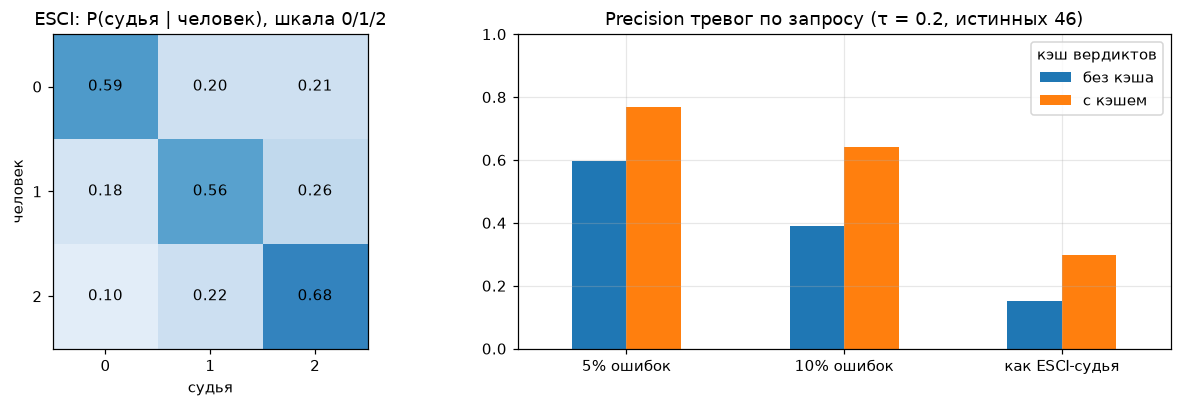

In [8]:
# Шум судьи в детекторе: релиз ломает 10% запросов, судья оценивает топ-3 базы и релиза.
cur, _ = release(cands, SIGMA, seed=300, kind="evict_1", share=0.1)
truth = {q for q, v in delta_ndcg(base, cur, ideal).items() if v <= -TAU}
rows = []
for name, c in {
    "5% ошибок": uniform_confusion(0.05),
    "10% ошибок": uniform_confusion(0.10),
    "как ESCI-судья": conf,
}.items():
    for cache in (False, True):
        flag = {q for q, v in delta_ndcg(base, cur, ideal, c, cache).items() if v <= -TAU}
        rows.append(
            {
                "судья": name,
                "кэш вердиктов": "с кэшем" if cache else "без кэша",
                "тревог": len(flag),
                "precision": len(flag & truth) / len(flag),
                "recall": len(flag & truth) / len(truth),
            }
        )
det = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
im = ax[0].imshow(conf, cmap="Blues", vmin=0, vmax=1)
for (a, b), v in np.ndenumerate(conf):
    ax[0].text(b, a, f"{v:.2f}", ha="center", va="center")
ax[0].set(
    title="ESCI: P(судья | человек), шкала 0/1/2",
    xlabel="судья",
    ylabel="человек",
    xticks=[0, 1, 2],
    yticks=[0, 1, 2],
)
ax[0].grid(False)
det.pivot(index="судья", columns="кэш вердиктов", values="precision").loc[
    ["5% ошибок", "10% ошибок", "как ESCI-судья"]
].plot.bar(ax=ax[1], rot=0)
ax[1].set(
    title=f"Precision тревог по запросу (τ = {TAU}, истинных {len(truth)})", ylim=(0, 1), xlabel=""
)
fig.tight_layout()
fig.savefig(FIG + "q4_judge.png")
det

**Вывод.** По шкале 0/1/2 судья совпадает с людьми в 62,5% пар (κ 0,39), в бинарной свёртке — в 82% (но κ всё равно 0,40). Ошибается во все стороны: 22–26% на границе 1 ↔ 2 и 21% «нерелевантных» поднимает до 2. Хуже всего на однословных запросах (0,55) и на парах не из реальной выдачи (0,54 против 0,67). Шум судьи рождает ложные просадки: при 10% ошибок precision тревог 0,39 без кэша и 0,64 с кэшем вердиктов, при шуме уровня ESCI — 0,15 и 0,30, а recall падает до ~0,5.

**Решение:** судью «из коробки» не используем: калибруем на разметке Полины и допускаем к тревогам, только если ошибка по позиции ≤ 5–10%. Вердикты пар «запрос–фича» кэшируем между релизами и оцениваем только новые пары. Пока судья не откалиброван, каждую тревогу по запросу подтверждает человек; короткие запросы и оценки 1 ↔ 2 идут на ручную проверку.

## Сводка: квоты на разметку с Полиной

In [9]:
N_TOTAL = 400
quota = (
    (cat["section"].value_counts() / len(cat) * N_TOTAL)
    .clip(lower=15)
    .round()
    .astype(int)
    .rename("запросов")
)
quota.to_frame().assign(
    **{"живых запросов в прокси": cover[["banking77_ru", "ssq_ru"]].sum(axis=1)}
)

,запросов,живых запросов в прокси
section,,
Карты,58,493
Платежи и переводы,58,203
Управление картой,50,262
Пополнение,42,346
Профиль и безопасность,42,369
Валюта,25,213
Справка,25,346
Кредиты,25,12
Сбережения,25,25


**Итог:** ~410 запросов по квотам выше. Где живых запросов в прокси меньше квоты (кредиты, сбережения, ипотека), запросы берём только у Полины, это приоритет первой партии.